# clock/04 — newline transition probe (cross-modality contrastive)

**Goal.** Learn a linear probe that separates two kinds of `\n` tokens:

- **D+ (transition)** = condition line-ends in **monolithic** generations — each ends one predicate and moves on to the next (incl. the last cond→print).
- **D- (no transition)** = **interior** line-ends inside a **modular** predicate's multi-line body — the body continues, no move-on.

Tokens whose decoded text ends in `\n` count as newlines (absorbs `)\n`, `]\n`).

**Confound we must watch.** D+ is all-monolithic, D- is all-modular, so a probe could learn *style* not *transition*. The disentangling test (§8): evaluate the trained probe on **modular transition** newlines (segment-ends, never trained). If it calls them D+, it learned transition; if D-, it learned style.

Ported from `18.1` (TokenRow / HS-cache + token-demeaning / hinge+mean-diff / sweep).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

In [2]:
import os
import json
import random
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils, env_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5,6,7")

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
logging_utils.configure(level=logging.INFO)

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"
CACHE_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT)

mt = ModelandTokenizer(
    model_key=MODEL_NAME, dtype=torch.bfloat16, device_map="auto", attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}")

2026-06-10 19:59:09 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-10 19:59:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-10 19:59:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-10 19:59:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-10 19:59:09 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-10 19:59:09 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-10 19:59:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-10 19:59:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-10 19:59:31 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120


## 1. Load labeled generations (conditions, both modalities)

In [4]:
from src.goals.multistep_label import LabeledGeneration

MODALITIES = ["modular", "monolithic"]
records = []   # one per (sample, modularity)
for modularity in MODALITIES:
    mod_dir = os.path.join(CACHE_ROOT, modularity)
    if not os.path.isdir(mod_dir):
        print(f"  [warn] missing {mod_dir}"); continue
    for s in sorted(os.listdir(mod_dir)):
        lp = os.path.join(mod_dir, s, "labels.json")
        if not os.path.exists(lp):
            continue
        with open(lp) as f:
            lab = LabeledGeneration.from_dict(json.load(f))
        records.append({"sample_name": s, "modularity": modularity, "labeled": lab})

print(f"loaded {len(records)} records  "
      f"(modular={sum(r['modularity']=='modular' for r in records)}, "
      f"monolithic={sum(r['modularity']=='monolithic' for r in records)})")

loaded 1000 records  (modular=500, monolithic=500)


## 2. Build D+ / D- position sets

Newline = a generated token whose decoded text ends in `\n` (absorbs `)\n`, `]\n`). For each predicate's real code lines, the **final** line-end is the *transition*, the rest are *interior*. Roles:

| role | modality | line | train? |
|---|---|---|---|
| `trans_mono` (D+) | monolithic | final | **train +** |
| `nontrans_mod` (D-) | modular | interior | **train −** |
| `trans_mod` | modular | final | held-out (§8) |
| `nontrans_mono` | monolithic | interior | held-out (rare) |

In [5]:
import re
from dataclasses import dataclass

#############################################################
LAG = 0   # probe position = newline token - LAG  (0 = at the newline)
BLACKLIST_COLON_NL = True    # drop newline tokens ending in ':\n' (if/for/while/def lines)
#############################################################
_BLACKLIST_RE = re.compile(r":\n+$")
N_BLACKLISTED = 0
def _blacklisted(tok_str):
    return BLACKLIST_COLON_NL and bool(_BLACKLIST_RE.search(tok_str))


ROLE_POS = "trans_mono"      # D+
ROLE_NEG = "nontrans_mod"    # D-
ROLE_HPOS = "trans_mod"      # held-out positive (modular segment-end) — the §8 test
ROLE_HNEG = "nontrans_mono"  # held-out (monolithic interior, rare)


@dataclass
class TokenRow:
    sample_name: str
    modularity: str
    step_idx: int
    role: str
    token_pos: int
    first_token_str: str
    token_id: int = -1


def _char_to_token(offsets, char_idx):
    for j, (a, b) in enumerate(offsets):
        if b > a and a <= char_idx < b:
            return j
    return None


def _enc(lab):
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    return combined, [tuple(p) for p in enc["offset_mapping"]], enc["input_ids"], len(lab.full_prompt)


def _real_code_lines(lab, sl, el, char_offset):
    """(line_no, line_start_char, line_str) for non-blank lines in [sl, el]."""
    gen_lines = lab.generation.splitlines(keepends=True)
    sl = max(1, sl); el = min(el, len(gen_lines)); cum = 0
    out = []
    for li, line in enumerate(gen_lines, start=1):
        lsc = char_offset + cum; cum += len(line)
        if li < sl or li > el or line.strip() == "":
            continue
        out.append((li, lsc, line))
    return out


def extract_newline_rows(record):
    global N_BLACKLISTED
    lab = record["labeled"]
    _, offsets, input_ids, char_offset = _enc(lab)
    is_mono = record["modularity"] == "monolithic"
    rows = []
    for i, step in enumerate(lab.labels):
        if step.gen_line_range is None:
            continue
        lines = _real_code_lines(lab, *step.gen_line_range, char_offset)
        if not lines:
            continue
        final_li = max(li for li, _, _ in lines)
        for li, lsc, line in lines:
            nl_char = lsc + len(line) - 1          # last char of the line (the '\n')
            t = _char_to_token(offsets, nl_char)
            if t is None:
                continue
            ts = t - LAG
            if ts < 0:
                continue
            tok_str = mt.tokenizer.decode([input_ids[ts]])
            if _blacklisted(tok_str):
                N_BLACKLISTED += 1
                continue
            is_final = (li == final_li)
            if is_mono:
                role = ROLE_POS if is_final else ROLE_HNEG
            else:
                role = ROLE_HPOS if is_final else ROLE_NEG
            rows.append(TokenRow(record["sample_name"], record["modularity"], i, role, ts,
                                 tok_str, input_ids[ts]))
    return rows


all_rows = []
N_BLACKLISTED = 0
for r in records:
    all_rows.extend(extract_newline_rows(r))

role_counts = pd.Series([r.role for r in all_rows]).value_counts().to_dict()
print(f"{len(all_rows)} rows  {role_counts}   (blacklisted {N_BLACKLISTED} ':\\n' tokens)")
for role in [ROLE_POS, ROLE_NEG, ROLE_HPOS, ROLE_HNEG]:
    toks = pd.Series([r.first_token_str for r in all_rows if r.role == role]).value_counts().head(6)
    print(f"\n{role} top tokens: {toks.to_dict()}")

4474 rows  {'trans_mod': 1999, 'trans_mono': 1999, 'nontrans_mod': 476}   (blacklisted 2052 ':\n' tokens)

trans_mono top tokens: {'\n': 1788, ']\n': 175, '))\n': 36}

nontrans_mod top tokens: {'\n': 327, ')\n': 104, '))\n': 36, '\n\n': 5, ']\n\n': 4}

trans_mod top tokens: {'\n\n': 1520, ')\n': 182, ']\n\n': 158, '\n': 135, ')))\n\n': 2, ')\n\n': 1}

nontrans_mono top tokens: {}


## 2b. Validate labeling

In [6]:
from rich.text import Text

def _vis(s): return s.replace("\n", "\u21b5\n").replace("\t", "\u21e5")
ROLE_STYLE = {ROLE_POS: "bold black on green", ROLE_NEG: "bold black on red",
              ROLE_HPOS: "bold black on cyan", ROLE_HNEG: "bold black on magenta"}

def render_record(record):
    lab = record["labeled"]
    _, offsets, ids, char_offset = _enc(lab)
    gen_start = next(j for j, (a, b) in enumerate(offsets) if a >= char_offset and b > a)
    k = (record["sample_name"], record["modularity"])
    role_at = {r.token_pos: r.role for r in all_rows if (r.sample_name, r.modularity) == k}
    rich_print(f"[bold]{record['sample_name']} · {record['modularity']}[/bold]  (LAG={LAG})")
    rich_print("legend: [bold black on green] D+ trans_mono [/] "
               "[bold black on red] D- nontrans_mod [/] "
               "[bold black on cyan] trans_mod (held) [/] "
               "[bold black on magenta] nontrans_mono [/]")
    txt = Text()
    for t in range(len(ids)):
        if t == gen_start:
            txt.append("\n" + "\u2500" * 30 + " GENERATION " + "\u2500" * 30 + "\n", style="bold grey42")
        s = _vis(mt.tokenizer.decode([ids[t]]))
        if t < gen_start:
            txt.append(s, style="grey42"); continue
        txt.append(s, style=ROLE_STYLE.get(role_at.get(t), "grey58"))
    console.print(txt)

render_record(next(r for r in records if r["modularity"] == "monolithic" and len(r["labeled"].labels) >= 3))
render_record(next(r for r in records if r["modularity"] == "modular" and len(r["labeled"].labels) >= 3))

cond_0000 · monolithic  (LAG=0)

legend:  D+ trans_mono   D- nontrans_mod   trans_mod (held)   nontrans_mono 

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. n is less than or equal to 500↵
2. n is positive↵
3. n is a perfect square↵
4. n is between 10 and 200 (inclusive)↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def check_conditions(n: int):↵

────────────────────────────── GENERATION ──────────────────────────────
    a = n <= 500↵
    b = n > 0↵
    c = int(n**0.5)**2 == n↵
    d = 10 <= n <= 200↵
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, all: {a and b and c and d}")↵
</code>

cond_0000 · modular  (LAG=0)

legend:  D+ trans_mono   D- nontrans_mod   trans_mod (held)   nontrans_mono 

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. n is less than or equal to 500↵
2. n is positive↵
3. n is a perfect square↵
4. n is between 10 and 200 (inclusive)↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Implement each condition as a separate function that returns a bool; inside `check_conditions`, call these 
functions in the order listed to compute the per-condition result variables.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵

────────────────────────────── GENERATION ──────────────────────────────
def is_le_500(n):↵
    return n <= 500↵
↵
def is_positive(n):↵
    return n > 0↵
↵
def is_perfect_square(n):↵
    import math↵
    return math.isqrt(n) ** 2 == n↵
↵
def is_between_10_and_200(n):↵
    return 10 <= n <= 200↵
↵
def check_conditions(n):↵
    a = is_le_500(n)↵
    b = is_positive(n)↵
    c = is_perfect_square(n)↵
    d = is_between_10_and_200(n)↵
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All Conditions: {a and b and c 
and d}")↵
</code>

## 3. Extract hidden states (+ per-token-id means for demeaning)

In [7]:
from src.functional import get_hs
from src.tokens import prepare_input
from collections import defaultdict

LAYERS_SWEEP = list(range(0, mt.n_layer, 4))
if (mt.n_layer - 1) not in LAYERS_SWEEP:
    LAYERS_SWEEP.append(mt.n_layer - 1)
LAYERS_SWEEP = sorted(LAYERS_SWEEP)
LAYER_KEYS = ["emb"] + LAYERS_SWEEP
print(f"sweeping {len(LAYER_KEYS)} layers: {LAYER_KEYS}")

def layer_key_to_name(L): return mt.embedder_name if L == "emb" else mt.layer_names[L]
def _plot_x(L): return -1 if L == "emb" else L
def _layer_label(L): return "emb" if L == "emb" else str(L)
def apply_layer_axis(ax, keys=None):
    keys = list(keys) if keys is not None else LAYER_KEYS
    ax.set_xticks([_plot_x(L) for L in keys]); ax.set_xticklabels([_layer_label(L) for L in keys])

key = lambda r: (r.sample_name, r.modularity)
positions_per_record = {}
for r in all_rows:
    positions_per_record.setdefault(key(r), set()).add(r.token_pos)

PROBE_TOKEN_IDS = {r.token_id for r in all_rows}
MAX_PER_TOKEN = 500
KAPPA = 0.0

hs_cache = {}
_tok_sum = {L: {} for L in LAYER_KEYS}
_tok_cnt = {L: defaultdict(int) for L in LAYER_KEYS}
_tok_cnt_global = defaultdict(int)


@torch.no_grad()
def cache_one(record):
    k = (record["sample_name"], record["modularity"])
    if k in hs_cache:
        return
    probe_positions = sorted(positions_per_record.get(k, set()))
    combined = record["labeled"].full_prompt + record["labeled"].generation
    tokenized = prepare_input(prompts=combined, tokenizer=mt)
    input_ids = tokenized.input_ids[0].tolist()
    mean_positions = [t for t, tid in enumerate(input_ids)
                      if tid in PROBE_TOKEN_IDS and _tok_cnt_global[tid] < MAX_PER_TOKEN]
    fetch = sorted(set(probe_positions) | set(mean_positions))
    if not fetch:
        hs_cache[k] = {L: {} for L in LAYER_KEYS}; return
    layer_names = [layer_key_to_name(L) for L in LAYER_KEYS]
    hs_dict = get_hs(mt=mt, input=tokenized,
                     locations=[(ly, t) for ly in layer_names for t in fetch], return_dict=True)
    out = {}
    for L, ly in zip(LAYER_KEYS, layer_names):
        out[L] = {t: hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float16) for t in probe_positions}
    hs_cache[k] = out
    for t in mean_positions:
        tid = input_ids[t]; _tok_cnt_global[tid] += 1
        for L, ly in zip(LAYER_KEYS, layer_names):
            v = hs_dict[(ly, t)].detach().to("cpu", dtype=torch.float32)
            _tok_sum[L][tid] = v.clone() if tid not in _tok_sum[L] else _tok_sum[L][tid] + v
            _tok_cnt[L][tid] += 1


for r in tqdm(records, desc="hs"):
    try:
        cache_one(r)
    except Exception as e:
        print(f"  [warn] {r['sample_name']}/{r['modularity']}: {e}")

TOKEN_MEANS = {}
for L in LAYER_KEYS:
    means = {}
    for tid, s in _tok_sum[L].items():
        means[tid] = s / _tok_cnt[L][tid]
    TOKEN_MEANS[L] = means
print(f"cached HS for {len(hs_cache)} records; {len(PROBE_TOKEN_IDS)} probe token-ids")

sweeping 18 layers: ['emb', 0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 63]


hs:   0%|          | 0/1000 [00:00<?, ?it/s]

cached HS for 1000 records; 8 probe token-ids


### 3b. Token fixed-effects demeaning — overlap check

In [8]:
from collections import Counter

pos_ids = Counter(r.token_id for r in all_rows if r.role == ROLE_POS)
neg_ids = Counter(r.token_id for r in all_rows if r.role == ROLE_NEG)
pt, nt = set(pos_ids), set(neg_ids)
jacc = len(pt & nt) / max(1, len(pt | nt))
print(f"D+ token types={len(pt)}  D- types={len(nt)}  shared={len(pt & nt)}  Jaccard={jacc:.2f}")
dec = mt.tokenizer.decode
print("  D+ top:", {dec([t]): c for t, c in pos_ids.most_common(6)})
print("  D- top:", {dec([t]): c for t, c in neg_ids.most_common(6)})
print("  (high token overlap ⇒ contrast is not pure token-identity ⇒ should survive demeaning)")

D+ token types=3  D- types=5  shared=2  Jaccard=0.33
  D+ top: {'\n': 1788, ']\n': 175, '))\n': 36}
  D- top: {'\n': 327, ')\n': 104, '))\n': 36, '\n\n': 5, ']\n\n': 4}
  (high token overlap ⇒ contrast is not pure token-identity ⇒ should survive demeaning)


## 4. Train/test split (by spec) + random cross-record pairs

Split on the spec dir name (so a spec is entirely train or test). Pairs are random (any monolithic D+ × any modular D-), per the chosen design.

In [9]:
SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000
TEST_LIMIT = 4000
DEMEAN = False
DEMEAN_ZERO_TOL = 1e-4
rng = random.Random(SEED)

spec_names = sorted({r["sample_name"] for r in records})
shuffled = list(spec_names); rng.shuffle(shuffled)
n_test = max(1, int(len(shuffled) * TEST_FRAC))
test_names = set(shuffled[:n_test]); train_names = set(shuffled[n_test:])
print(f"split: train={len(train_names)} test={len(test_names)} specs")

def pool(rows, role, names):
    return [r for r in rows if r.role == role and r.sample_name in names]

def sample_pairs(pos_pool, neg_pool, n, rng_local):
    if not pos_pool or not neg_pool:
        return []
    return [(rng_local.choice(pos_pool), rng_local.choice(neg_pool)) for _ in range(n)]

pos_tr = pool(all_rows, ROLE_POS, train_names); neg_tr = pool(all_rows, ROLE_NEG, train_names)
pos_te = pool(all_rows, ROLE_POS, test_names);  neg_te = pool(all_rows, ROLE_NEG, test_names)
pairs_train = sample_pairs(pos_tr, neg_tr, TRAIN_LIMIT, rng)
pairs_test  = sample_pairs(pos_te, neg_te, TEST_LIMIT, random.Random(1))
print(f"train pool D+={len(pos_tr)} D-={len(neg_tr)}  test pool D+={len(pos_te)} D-={len(neg_te)}")
print(f"pairs train={len(pairs_train)} test={len(pairs_test)}")

split: train=400 test=100 specs
train pool D+=1600 D-=379  test pool D+=399 D-=97
pairs train=10000 test=4000


## 5. Optimize direction (hinge) + mean-diff baseline

In [10]:
def hs_at(row, layer_idx, normalize=True):
    k = (row.sample_name, row.modularity)
    h = hs_cache[k][layer_idx][row.token_pos].to(torch.float32)
    denom = h.norm() + 1e-9
    if DEMEAN:
        mu = TOKEN_MEANS.get(layer_idx, {}).get(row.token_id)
        if mu is None:
            raise KeyError(f"DEMEAN but no mean for layer={layer_idx} tok={row.token_id}")
        resid = h - mu
        if resid.norm() < DEMEAN_ZERO_TOL * denom:
            return torch.zeros_like(h)
        h = resid
    if normalize:
        h = h / denom
    return h

def stack_rows(rows, layer_idx, normalize=True):
    return torch.stack([hs_at(r, layer_idx, normalize) for r in rows], dim=0)

def optimize_direction(pos_rows, neg_rows, pair_idx, layer_idx, *, margin=0.1, lr=1e-2,
                       n_steps=300, batch_size=1024, seed=0, device="cuda", random_init=False):
    Zp = torch.stack([hs_at(pos_rows[i], layer_idx) for i, _ in pair_idx]).to(device)
    Zn = torch.stack([hs_at(neg_rows[j], layer_idx) for _, j in pair_idx]).to(device)
    diffs = (Zp - Zn).contiguous(); d, N = diffs.shape[-1], diffs.shape[0]
    init = Zp.mean(0) - Zn.mean(0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]; v_u = v / (v.norm() + 1e-9)
        loss = torch.clamp(margin - (b * v_u).sum(-1), min=0).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return (v / (v.norm() + 1e-9)).detach().cpu(), {}

def mean_diff_direction(pos_rows, neg_rows, layer_idx):
    v = stack_rows(pos_rows, layer_idx).mean(0) - stack_rows(neg_rows, layer_idx).mean(0)
    return v / (v.norm() + 1e-9)

## 6. Layer sweep

In [11]:
MARGIN, LR, N_STEPS = 0.1, 1e-2, 300

def constraint_sat(v, pairs, layer_key):
    if not pairs:
        return float("nan")
    diffs = torch.stack([hs_at(p, layer_key) - hs_at(n, layer_key) for p, n in pairs])
    return ((diffs * v).sum(-1) > 0).float().mean().item()

pos_rows_tr = [p for p, _ in pairs_train]
neg_rows_tr = [n for _, n in pairs_train]
pair_idx = [(i, i) for i in range(len(pairs_train))]

sweep_results = []
for L in LAYER_KEYS:
    v_opt, _ = optimize_direction(pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
                                  margin=MARGIN, lr=LR, n_steps=N_STEPS)
    v_md = mean_diff_direction(pos_rows_tr, neg_rows_tr, L)
    sat_opt = constraint_sat(v_opt, pairs_test, L)
    sat_md = constraint_sat(v_md, pairs_test, L)
    sweep_results.append({"layer": L, "sat_test_opt": sat_opt, "sat_test_md": sat_md,
                          "v_opt": v_opt, "v_md": v_md})
    print(f"layer={_layer_label(L):>3s}  sat_te_opt={sat_opt:.3f}  sat_te_md={sat_md:.3f}")

best_row = max((r for r in sweep_results if r["layer"] != "emb"), key=lambda r: r["sat_test_opt"])
best_layer = best_row["layer"]
print(f"\nbest layer (hinge, held-out) = {_layer_label(best_layer)}  sat={best_row['sat_test_opt']:.3f}")

layer=emb  sat_te_opt=0.375  sat_te_md=0.319
layer=  0  sat_te_opt=0.999  sat_te_md=0.920
layer=  4  sat_te_opt=1.000  sat_te_md=0.989
layer=  8  sat_te_opt=1.000  sat_te_md=0.996
layer= 12  sat_te_opt=1.000  sat_te_md=0.985
layer= 16  sat_te_opt=1.000  sat_te_md=0.978
layer= 20  sat_te_opt=1.000  sat_te_md=0.981
layer= 24  sat_te_opt=1.000  sat_te_md=0.970
layer= 28  sat_te_opt=1.000  sat_te_md=0.972
layer= 32  sat_te_opt=1.000  sat_te_md=0.971
layer= 36  sat_te_opt=1.000  sat_te_md=0.971
layer= 40  sat_te_opt=1.000  sat_te_md=0.970
layer= 44  sat_te_opt=1.000  sat_te_md=0.969
layer= 48  sat_te_opt=1.000  sat_te_md=0.974
layer= 52  sat_te_opt=1.000  sat_te_md=0.977
layer= 56  sat_te_opt=1.000  sat_te_md=0.972
layer= 60  sat_te_opt=1.000  sat_te_md=0.974
layer= 63  sat_te_opt=1.000  sat_te_md=0.981

best layer (hinge, held-out) = 4  sat=1.000


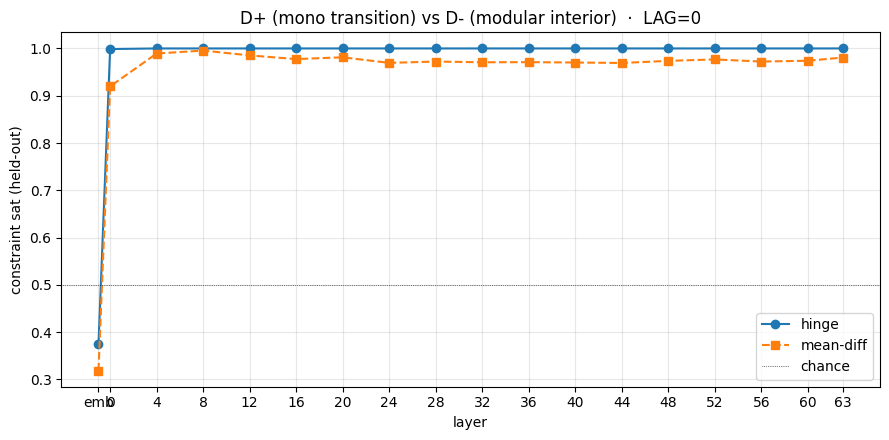

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
df = pd.DataFrame(sweep_results); df["x"] = df["layer"].map(_plot_x); df = df.sort_values("x")
ax.plot(df["x"], df["sat_test_opt"], "o-", label="hinge")
ax.plot(df["x"], df["sat_test_md"], "s--", label="mean-diff")
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out)")
ax.set_title(f"D+ (mono transition) vs D- (modular interior)  ·  LAG={LAG}")
apply_layer_axis(ax); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 6b. Raw vs token-demeaned sweep

If the contrast survives token fixed-effects demeaning, it is not merely the `\n` vs `\n\n` (or `)\n`) token-identity difference.

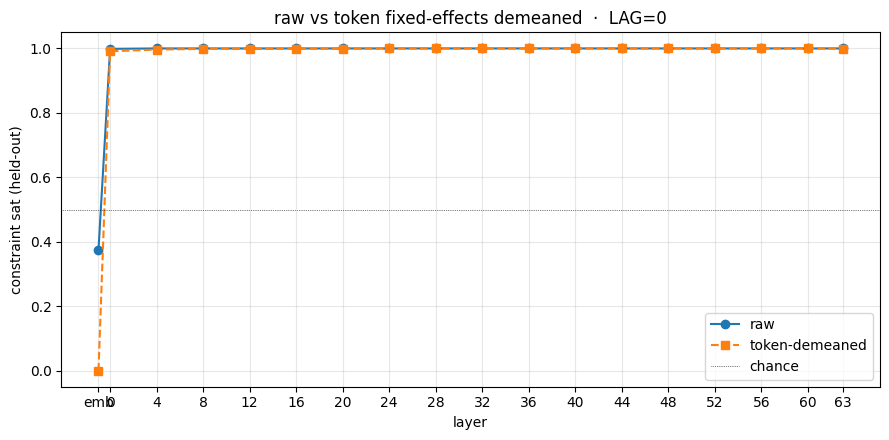

In [13]:
def _sweep_once(demean):
    global DEMEAN; DEMEAN = demean; out = []
    for L in LAYER_KEYS:
        v_opt, _ = optimize_direction(pos_rows_tr, neg_rows_tr, pair_idx, layer_idx=L,
                                      margin=MARGIN, lr=LR, n_steps=N_STEPS)
        out.append({"layer": L, "sat": constraint_sat(v_opt, pairs_test, L)})
    return out

_prev = DEMEAN
sweep_raw = _sweep_once(False)
sweep_dm = _sweep_once(True)
DEMEAN = _prev

fig, ax = plt.subplots(figsize=(9, 4.5))
for sw, lab_, sty in [(sweep_raw, "raw", "o-"), (sweep_dm, "token-demeaned", "s--")]:
    d = pd.DataFrame(sw); d["x"] = d["layer"].map(_plot_x); d = d.sort_values("x")
    ax.plot(d["x"], d["sat"], sty, label=lab_)
ax.axhline(0.5, color="k", lw=0.5, ls=":", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint sat (held-out)")
ax.set_title(f"raw vs token fixed-effects demeaned  ·  LAG={LAG}")
apply_layer_axis(ax); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Disentangling test — transition vs style

Project the trained probe (hinge, best layer; sign: D+ high) on four held-out groups: `trans_mono` (D+), `nontrans_mod` (D-), and the **never-trained** `trans_mod` (modular segment-ends). Threshold = midpoint of train D+/D- means. If `trans_mod` lands on the **D+ side**, the probe transfers across modality → it captured *transition*, not *monolithic style*. If it lands with D-, it learned style.

best layer=4  threshold=0.019
  mean proj  D+=0.092  D-=-0.055  trans_mod=-0.033
  >>> trans_mod classified as D+ (transition): 7.3%  (does NOT transfer — style confound)


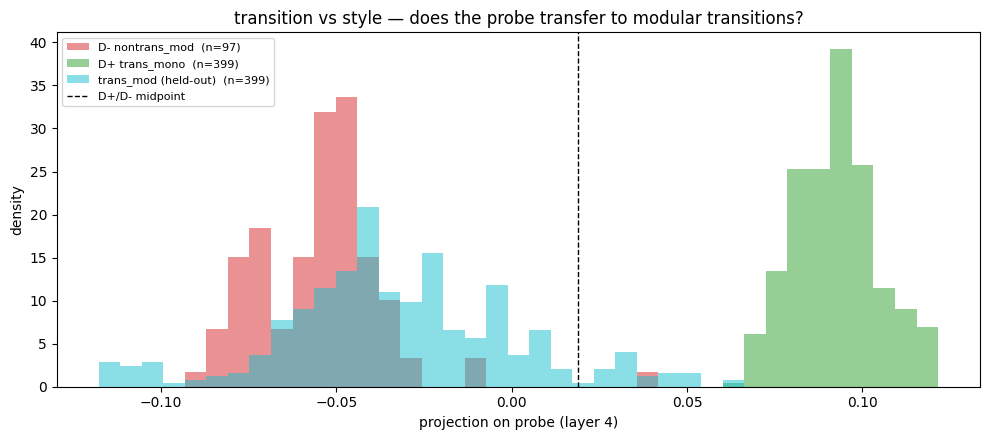

In [14]:
L = best_layer
v = best_row["v_opt"]

def proj(rows):
    return np.array([(hs_at(r, L) @ v).item() for r in rows]) if rows else np.array([])

g_pos = proj(pool(all_rows, ROLE_POS, test_names))
g_neg = proj(pool(all_rows, ROLE_NEG, test_names))
g_hpos = proj(pool(all_rows, ROLE_HPOS, test_names))   # modular transition (the test)
g_hneg = proj(pool(all_rows, ROLE_HNEG, test_names))   # monolithic interior (rare)

thr = (g_pos.mean() + g_neg.mean()) / 2
print(f"best layer={_layer_label(L)}  threshold={thr:.3f}")
print(f"  mean proj  D+={g_pos.mean():.3f}  D-={g_neg.mean():.3f}  "
      f"trans_mod={g_hpos.mean():.3f}" + (f"  nontrans_mono={g_hneg.mean():.3f}" if len(g_hneg) else ""))
if len(g_hpos):
    rate = (g_hpos > thr).mean()
    print(f"  >>> trans_mod classified as D+ (transition): {rate:.1%}  "
          f"({'TRANSFERS — transition, not style' if rate > 0.5 else 'does NOT transfer — style confound'})")

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(min(g_pos.min(), g_neg.min(), g_hpos.min() if len(g_hpos) else 0),
                   max(g_pos.max(), g_neg.max(), g_hpos.max() if len(g_hpos) else 0), 40)
for g, lab_, col in [(g_neg, "D- nontrans_mod", "tab:red"), (g_pos, "D+ trans_mono", "tab:green"),
                     (g_hpos, "trans_mod (held-out)", "tab:cyan")]:
    if len(g):
        ax.hist(g, bins=bins, alpha=0.5, density=True, color=col, label=f"{lab_}  (n={len(g)})")
ax.axvline(thr, color="k", ls="--", lw=1, label="D+/D- midpoint")
ax.set_xlabel(f"projection on probe (layer {_layer_label(L)})"); ax.set_ylabel("density")
ax.set_title("transition vs style — does the probe transfer to modular transitions?")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()